# Group Project 
## Nike (NKE) vs. Under Armour (UAA)

In [5]:
import sys
!"{sys.executable}" -m pip install pandas numpy matplotlib seaborn openpyxl yfinance


[notice] A new release of pip is available: 24.3.1 -> 26.3
[notice] To update, run: pip install --upgrade pip


In [6]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Pandas version:", pd.__version__)

Pandas version: 3.1.1


### Step 1 – Define the tickers (from Yahoo Finance)

In [7]:
tickers = {"Nike": "NKE", "Under_Armour": "UAA"}

### Step 2 – Fetch, merge, and clean the two time series

In [8]:
print("Fetching market data from Yahoo Finance...")
nke_data = yf.Ticker(tickers["Nike"]).history(period="1y")[["Close"]].rename(columns={"Close": "Nike_Close"})
uaa_data = yf.Ticker(tickers["Under_Armour"]).history(period="1y")[["Close"]].rename(columns={"Close": "Under_Armour_Close"})

# Merge by date and drop any incomplete rows (e.g., today's unfinished trading day)
combined_df = pd.merge(nke_data, uaa_data, left_index=True, right_index=True, how="inner").dropna()

# Remove the timezone but keep a real DatetimeIndex (needed for time series work in chapter 8)
combined_df.index = combined_df.index.tz_localize(None).normalize()
combined_df.index.name = "Date"

print("\nRecent Closing Prices (USD):")
print(combined_df.tail())
print("\nRows:", len(combined_df), "| Missing values:", combined_df.isna().sum().sum())

# Export the combined DataFrame to an Excel file
excel_filename = "nike_underarmour_data_export.xlsx"
combined_df.to_excel(excel_filename)
print(f"Data successfully exported to: {excel_filename}")

Fetching market data from Yahoo Finance...

Recent Closing Prices (USD):
            Nike_Close  Under_Armour_Close
Date                                      
2026-11-10   38.669998                5.16
2026-11-11   38.320000                5.01
2026-11-12   37.759998                4.90
2026-11-13   37.990002                4.91
2026-11-16   38.259998                4.85

Rows: 251 | Missing values: 0
Data successfully exported to: nike_underarmour_data_export.xlsx


### Data Visualizations

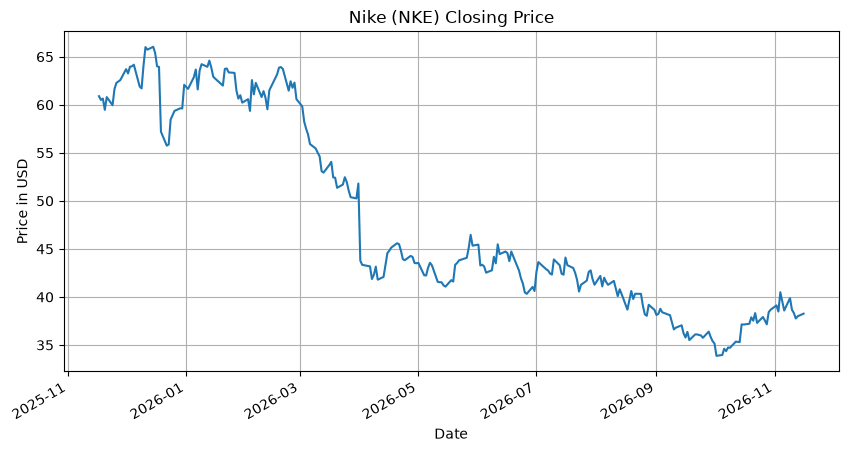

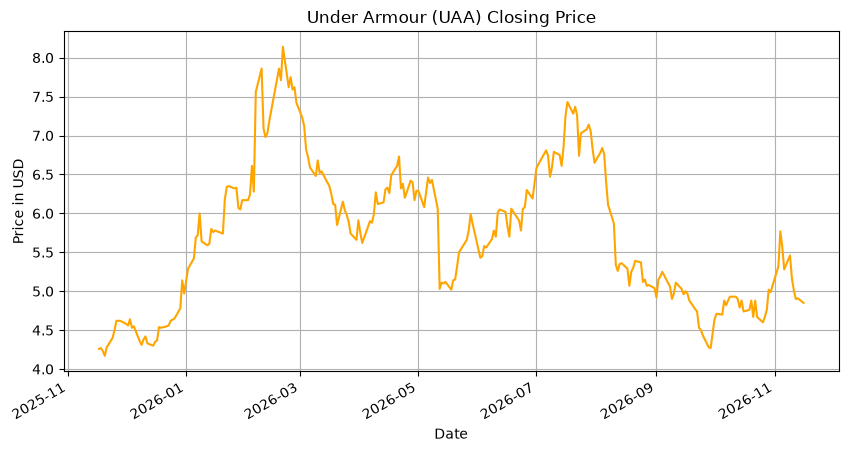

In [9]:
combined_df["Nike_Close"].plot(title="Nike (NKE) Closing Price", ylabel="Price in USD", grid=True, figsize=(10, 5))
plt.show()

combined_df["Under_Armour_Close"].plot(title="Under Armour (UAA) Closing Price", ylabel="Price in USD", grid=True, figsize=(10, 5), color="orange")
plt.show()